In [29]:
# Install (only if missing — Colab has TensorFlow, NumPy, Pandas, Matplotlib, Scikit-learn already)
!pip install tensorflow matplotlib scikit-learn pandas


In [30]:
import os
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [31]:
# ----------------------------
# STEP 1: Setup paths & hyperparameters
# ----------------------------
ZIP_PATH = "/content/archive.zip"
EXTRACT_DIR = "/content/archive"
IMG_SIZE = 224   # EfficientNetB0 input size
BATCH_SIZE = 32
SEED = 42
EPOCHS = 10

In [32]:
# ----------------------------
# STEP 2: Extract dataset
# ----------------------------
import os, zipfile
from pathlib import Path

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

In [33]:
# Detect dataset root folder
candidates = [p for p in Path(EXTRACT_DIR).iterdir() if p.is_dir()]
if len(candidates) == 1:
    DATA_ROOT = str(candidates[0])
else:
    DATA_ROOT = EXTRACT_DIR

print("Dataset root:", DATA_ROOT)

Dataset root: /content/archive/PlantVillageDataset


In [34]:
# ----------------------------
# STEP 3: Create train/val/test datasets
# ----------------------------
import tensorflow as tf
from tensorflow import keras

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT,
    validation_split=0.2,   # 80% train + 20% val
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Classes:", class_names)


Found 61914 files belonging to 2 classes.
Using 49532 files for training.
Found 61914 files belonging to 2 classes.
Using 12382 files for validation.
Classes: ['PlantVillage', 'train_val_test']


In [35]:
# Prefetching for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [36]:
# ----------------------------
# STEP 4: Data augmentation
# ----------------------------
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [37]:
# ----------------------------
# STEP 5: Build EfficientNetB0 model
# ----------------------------
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    pooling="avg"
)
base_model.trainable = False  # freeze backbone first

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x)
x = base_model(x, training=False)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,052,133 (15.46 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [38]:
# ----------------------------
# STEP 6: Train model
# ----------------------------
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 157s 93ms/step - accuracy: 0.6216 - loss: 0.6776 - val_accuracy: 0.6707 - val_loss: 0.6415
Epoch 2/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 154s 100ms/step - accuracy: 0.6499 - loss: 0.6566 - val_accuracy: 0.6715 - val_loss: 0.6386
Epoch 3/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 202s 100ms/step - accuracy: 0.6543 - loss: 0.6511 - val_accuracy: 0.6716 - val_loss: 0.6377
Epoch 4/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 154s 100ms/step - accuracy: 0.6593 - loss: 0.6479 - val_accuracy: 0.6715 - val_loss: 0.6376
Epoch 5/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 202s 100ms/step - accuracy: 0.6617 - loss: 0.6466 - val_accuracy: 0.6719 - val_loss: 0.6374
Epoch 6/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 202s 99ms/step - accuracy: 0.6620 - loss: 0.6461 - val_accuracy: 0.6719 - val_loss: 0.6373
Epoch 7/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 186s 89ms/step - accuracy: 0.6632 - loss: 0.6440 - val_accuracy: 0.6719 - val_loss: 0.6372
Epoch 8/10
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 158s 100ms/step - accur

In [39]:
# ----------------------------
# STEP 7: Fine-tune (optional)
# ----------------------------
base_model.trainable = True  # unfreeze backbone
model.compile(
    optimizer=keras.optimizers.Adam(1e-5),  # lower LR for fine-tuning
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 601s 364ms/step - accuracy: 0.5979 - loss: 0.6711 - val_accuracy: 0.6707 - val_loss: 0.6434
Epoch 2/5
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 616s 360ms/step - accuracy: 0.6619 - loss: 0.6463 - val_accuracy: 0.6711 - val_loss: 0.6425
Epoch 3/5
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 562s 360ms/step - accuracy: 0.6620 - loss: 0.6465 - val_accuracy: 0.6718 - val_loss: 0.6414
Epoch 4/5
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 559s 361ms/step - accuracy: 0.6634 - loss: 0.6442 - val_accuracy: 0.6718 - val_loss: 0.6414
Epoch 5/5
1548/1548 ━━━━━━━━━━━━━━━━━━━━ 547s 351ms/step - accuracy: 0.6635 - loss: 0.6431 - val_accuracy: 0.6718 - val_loss: 0.6413


In [40]:
# ----------------------------
# STEP 8: Evaluate
# ----------------------------
loss, acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {acc:.4f}")

387/387 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - accuracy: 0.6736 - loss: 0.6403
Validation Accuracy: 0.6718


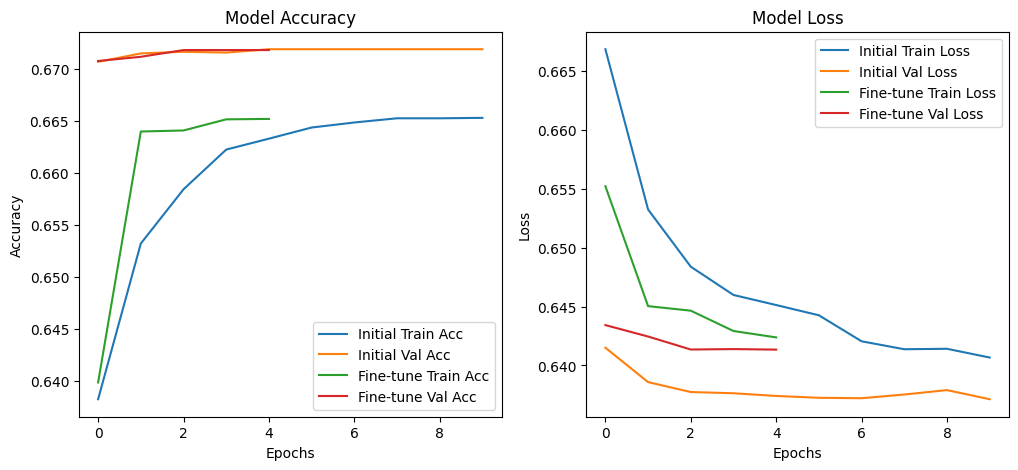

In [41]:
# ----------------------------
# Plot Accuracy & Loss curves
# ----------------------------
def plot_history(histories):
    plt.figure(figsize=(12,5))

    # Accuracy
    plt.subplot(1,2,1)
    for label, history in histories.items():
        plt.plot(history.history['accuracy'], label=f'{label} Train Acc')
        plt.plot(history.history['val_accuracy'], label=f'{label} Val Acc')
    plt.title("Model Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    for label, history in histories.items():
        plt.plot(history.history['loss'], label=f'{label} Train Loss')
        plt.plot(history.history['val_loss'], label=f'{label} Val Loss')
    plt.title("Model Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    plt.show()

plot_history({"Initial": history, "Fine-tune": history_fine})

In [43]:
# ----------------------------
# STEP 9: Save model
# ----------------------------
model.save("/content/efficientnetb0_model.h5")
print("Model saved to /content/efficientnetb0_model.h5")

Model saved to /content/efficientnetb0_model.h5
